# 🤖 Notebook 3: Xây dựng và Đánh giá Mô hình ML
## Đề tài: Phân tích và Dự đoán Khách hàng Rời bỏ (Customer Churn Prediction)

---

### Các mô hình sẽ xây dựng:
1. **Logistic Regression** — Baseline, dễ diễn giải
2. **Decision Tree** — Trực quan, dễ giải thích
3. **Random Forest** — Ensemble mạnh, cho Feature Importance
4. **Gradient Boosting** — Hiệu năng cao

### Metrics đánh giá:
- **ROC-AUC** (metric chính)
- **F1-Score** (cân bằng Precision-Recall)
- **Recall** (quan trọng: bắt đúng khách hàng sẽ rời bỏ)
- **Confusion Matrix**

> ⚠️ **KHÔNG dùng Accuracy** làm metric chính vì dữ liệu mất cân bằng (73% No, 27% Yes)

In [1]:
# ============================================================
# IMPORT THƯ VIỆN
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Sklearn Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Sklearn Utilities
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, auc, f1_score, precision_score, recall_score,
    accuracy_score, precision_recall_curve
)

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 120
sns.set_style('whitegrid')

print('✅ Import thư viện thành công!')
print()
print('📦 Các mô hình sẽ dùng:')
print('   1. LogisticRegression (sklearn) – Baseline')
print('   2. DecisionTreeClassifier (sklearn)')
print('   3. RandomForestClassifier (sklearn) ⭐ Khuyến nghị')
print('   4. GradientBoostingClassifier (sklearn)')

✅ Import thư viện thành công!

📦 Các mô hình sẽ dùng:
   1. LogisticRegression (sklearn) – Baseline
   2. DecisionTreeClassifier (sklearn)
   3. RandomForestClassifier (sklearn) ⭐ Khuyến nghị
   4. GradientBoostingClassifier (sklearn)


---
## 1. Tải Dữ liệu Đã Xử lý

In [2]:
# ============================================================
# TẢI DỮ LIỆU ĐÃ CLEAN TỪ NOTEBOOK 2
# ============================================================
# Nếu chưa chạy Notebook 2, chạy lại toàn bộ pipeline cleaning ở đây:

def load_and_clean_data(filepath='../data/raw/telco_churn.csv' if os.path.exists('../data/raw/telco_churn.csv') else 'data/raw/telco_churn.csv'):
    """Pipeline đầy đủ: Load → Clean → Encode → Scale"""
    df = pd.read_csv(filepath)
    
    # 1. Drop customerID
    df.drop('customerID', axis=1, inplace=True)
    
    # 2. TotalCharges: Convert + Imputation (MAR)
    df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
    df['TotalCharges'] = df['TotalCharges'].fillna(df['MonthlyCharges'])
    
    # 3. SeniorCitizen: 0/1 → Yes/No
    df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})
    
    # 4. Chuẩn hóa giá trị dịch vụ
    service_cols = ['MultipleLines', 'OnlineSecurity', 'OnlineBackup',
                    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
    for col in service_cols:
        df[col] = df[col].replace({'No internet service': 'No', 'No phone service': 'No'})
    
    # 5. Feature Engineering
    df['AvgChargePerMonth'] = df['TotalCharges'] / (df['tenure'] + 1)
    all_service_cols = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
                        'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
    df['NumServices'] = df[all_service_cols].eq('Yes').sum(axis=1)
    
    # 6. Encode Target
    df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
    
    # 7. Label Encoding cho binary
    binary_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling',
                   'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                   'TechSupport', 'StreamingTV', 'StreamingMovies', 'SeniorCitizen']
    le = LabelEncoder()
    for col in binary_cols:
        df[col] = le.fit_transform(df[col])
    
    # 8. One-Hot Encoding
    df = pd.get_dummies(df, columns=['InternetService', 'Contract', 'PaymentMethod'], drop_first=True)
    bool_cols = df.select_dtypes(include='bool').columns
    df[bool_cols] = df[bool_cols].astype(int)
    
    return df


# Tải và xử lý
    f_path = '../data/raw/telco_churn.csv' if os.path.exists('../data/raw/telco_churn.csv') else 'data/raw/telco_churn.csv'
    df = load_and_clean_data(f_path)
print(f'✅ Dataset đã sẵn sàng: {df.shape[0]:,} hàng × {df.shape[1]} cột')
print(f'   NaN còn lại: {df.isnull().sum().sum()}')
df.head(3)

✅ Dataset đã sẵn sàng: 7,043 hàng × 26 cột
   NaN còn lại: 0


---
## 2. Tách Train / Test

In [3]:
# ============================================================
# TÁCH FEATURES VÀ TARGET
# ============================================================
X = df.drop('Churn', axis=1)
y = df['Churn']

print(f'Features (X): {X.shape}')
print(f'Target  (y): {y.shape}')
print(f'Danh sách features ({len(X.columns)} cột):')
for i, col in enumerate(X.columns, 1):
    print(f'  {i:2d}. {col}')

Features (X): (7043, 25)
Target  (y): (7043,)
Danh sách features (25 cột):
   1. gender
   2. SeniorCitizen
   3. Partner
   4. Dependents
   5. tenure
   6. PhoneService
   7. MultipleLines
   8. OnlineSecurity
   9. OnlineBackup
  10. DeviceProtection
  11. TechSupport
  12. StreamingTV
  13. StreamingMovies
  14. PaperlessBilling
  15. MonthlyCharges
  16. TotalCharges
  17. AvgChargePerMonth
  18. NumServices
  19. InternetService_Fiber optic
  20. InternetService_No
  21. Contract_One year
  22. Contract_Two year
  23. PaymentMethod_Credit card (automatic)
  24. PaymentMethod_Electronic check
  25. PaymentMethod_Mailed check


In [4]:
# ============================================================
# SCALING (quan trọng cho Logistic Regression)
# ============================================================
numeric_cols_scale = ['tenure', 'MonthlyCharges', 'TotalCharges', 
                      'AvgChargePerMonth', 'NumServices']
scaler = StandardScaler()
X[numeric_cols_scale] = scaler.fit_transform(X[numeric_cols_scale])
print('✅ StandardScaler áp dụng cho:', numeric_cols_scale)

✅ StandardScaler áp dụng cho: ['tenure', 'MonthlyCharges', 'TotalCharges', 'AvgChargePerMonth', 'NumServices']


In [5]:
# ============================================================
# TRAIN/TEST SPLIT (80/20, stratified)
# ============================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2,      # 20% test
    random_state=42,    # Reproducibility
    stratify=y          # Giữ tỉ lệ churn trong cả 2 tập
)

print('=== PHÂN CHIA DỮ LIỆU ===')
print(f'Train set: {X_train.shape[0]:,} mẫu ({X_train.shape[0]/len(X)*100:.0f}%)')
print(f'Test set : {X_test.shape[0]:,} mẫu ({X_test.shape[0]/len(X)*100:.0f}%)')
print()
print('Phân bố Churn trong Train:')
print(y_train.value_counts(normalize=True).round(3))
print('\nPhân bố Churn trong Test:')
print(y_test.value_counts(normalize=True).round(3))
print('\n→ stratify=y giúp tỉ lệ class nhất quán giữa train/test ✅')

=== PHÂN CHIA DỮ LIỆU ===
Train set: 5,634 mẫu (80%)
Test set : 1,409 mẫu (20%)

Phân bố Churn trong Train:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Phân bố Churn trong Test:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

→ stratify=y giúp tỉ lệ class nhất quán giữa train/test ✅


---
## 3. Hàm Đánh giá Mô hình

In [6]:
# ============================================================
# HÀM ĐÁNH GIÁ MÔ HÌNH
# ============================================================

results_summary = {}  # Lưu kết quả để so sánh

def evaluate_model(model, model_name, X_train, y_train, X_test, y_test, color='#3498db'):
    """Train và đánh giá mô hình đầy đủ."""
    
    print(f'\n{"="*60}')
    print(f'  MÔ HÌNH: {model_name}')
    print(f'{"="*60}')
    
    # Train
    model.fit(X_train, y_train)
    
    # Predict
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    # Metrics
    acc    = accuracy_score(y_test, y_pred)
    roc    = roc_auc_score(y_test, y_prob)
    f1     = f1_score(y_test, y_pred)
    prec   = precision_score(y_test, y_pred)
    rec    = recall_score(y_test, y_pred)
    
    # Cross-validation
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    cv_scores = cross_val_score(model, X, y, cv=cv, scoring='roc_auc')
    
    print(f'\n📊 METRICS TRÊN TEST SET:')
    print(f'   Accuracy   : {acc:.4f}  (⚠️ KHÔNG dùng làm metric chính vì imbalanced)')
    print(f'   ROC-AUC    : {roc:.4f}  ← METRIC CHÍNH')
    print(f'   F1-Score   : {f1:.4f}')
    print(f'   Precision  : {prec:.4f}')
    print(f'   Recall     : {rec:.4f}  ← Quan trọng: bắt được khách hàng rời bỏ')
    print(f'\n🔄 CROSS-VALIDATION (5-fold ROC-AUC):')
    print(f'   Scores: {[f"{s:.4f}" for s in cv_scores]}')
    print(f'   Mean  : {cv_scores.mean():.4f} ± {cv_scores.std():.4f}')
    
    print('\n📋 CLASSIFICATION REPORT:')
    print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))
    
    # Lưu kết quả
    results_summary[model_name] = {
        'Accuracy' : acc,
        'ROC-AUC'  : roc,
        'F1-Score' : f1,
        'Precision': prec,
        'Recall'   : rec,
        'CV-AUC-Mean': cv_scores.mean(),
        'y_prob'   : y_prob,
        'y_pred'   : y_pred,
        'model'    : model,
        'color'    : color
    }
    
    return model, y_pred, y_prob

print('✅ Hàm evaluate_model đã sẵn sàng!')

✅ Hàm evaluate_model đã sẵn sàng!


---
## 4. Mô hình 1: Logistic Regression (Baseline)

**Tại sao chọn Logistic Regression làm baseline?**
- Đơn giản, nhanh, dễ diễn giải
- Cho phép đọc hệ số (coefficients) để hiểu tầm quan trọng của features
- Phù hợp với bài toán phân loại nhị phân
- Dùng `class_weight='balanced'` để xử lý class imbalance

In [7]:
# ============================================================
# MÔ HÌNH 1: LOGISTIC REGRESSION
# ============================================================
lr_model = LogisticRegression(
    class_weight='balanced',  # Xử lý class imbalance
    random_state=42,
    max_iter=1000,
    C=1.0                     # Regularization (1.0 = default)
)

lr_model, lr_pred, lr_prob = evaluate_model(
    lr_model, 'Logistic Regression', 
    X_train, y_train, X_test, y_test,
    color='#3498db'
)


  MÔ HÌNH: Logistic Regression

📊 METRICS TRÊN TEST SET:
   Accuracy   : 0.7452  (⚠️ KHÔNG dùng làm metric chính vì imbalanced)
   ROC-AUC    : 0.8476  ← METRIC CHÍNH
   F1-Score   : 0.6217
   Precision  : 0.5130
   Recall     : 0.7888  ← Quan trọng: bắt được khách hàng rời bỏ

🔄 CROSS-VALIDATION (5-fold ROC-AUC):
   Scores: ['0.8625', '0.8470', '0.8594', '0.8310', '0.8403']
   Mean  : 0.8480 ± 0.0118

📋 CLASSIFICATION REPORT:
              precision    recall  f1-score   support

    No Churn       0.91      0.73      0.81      1035
       Churn       0.51      0.79      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.75      0.76      1409



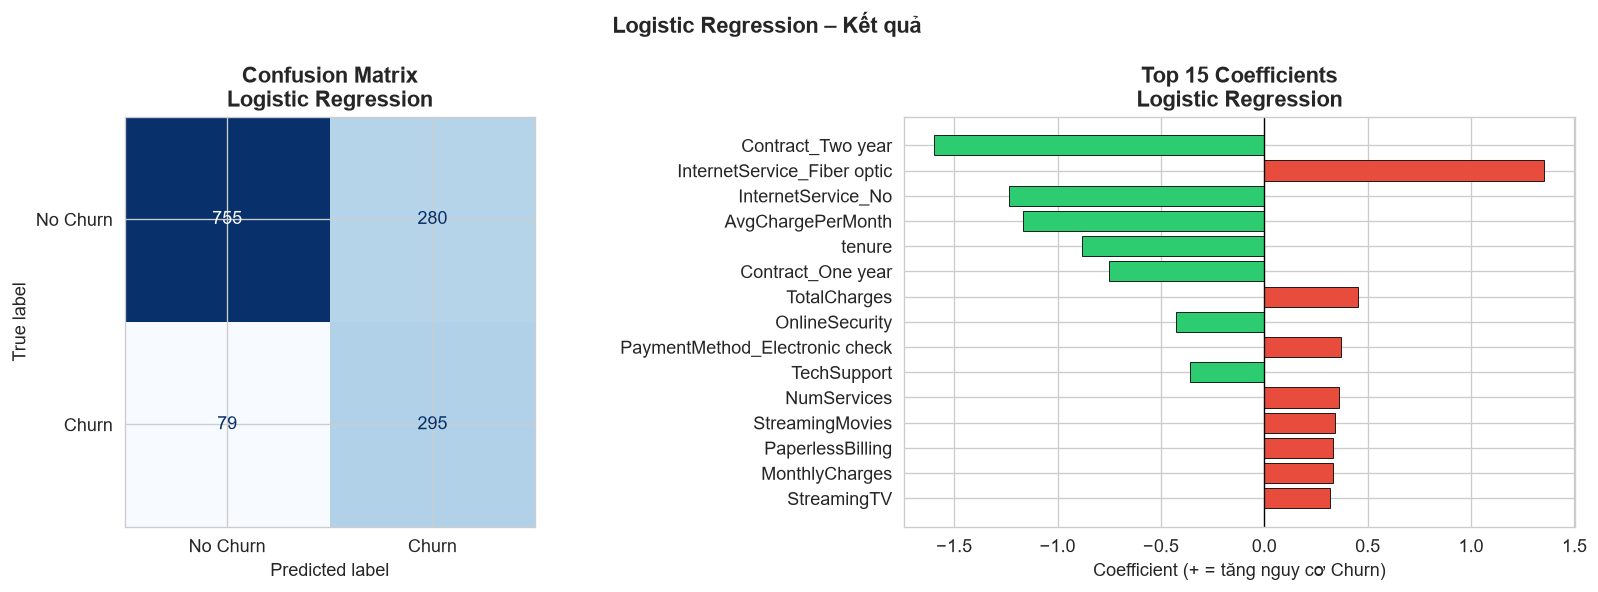

In [8]:
# Confusion Matrix - Logistic Regression
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, lr_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=['No Churn', 'Churn'])
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Confusion Matrix\nLogistic Regression', fontweight='bold')

# Feature importance (coefficients)
coef_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': lr_model.coef_[0]
}).sort_values('Coefficient', key=abs, ascending=True).tail(15)

colors_coef = ['#e74c3c' if c > 0 else '#2ecc71' for c in coef_df['Coefficient']]
axes[1].barh(coef_df['Feature'], coef_df['Coefficient'], color=colors_coef, edgecolor='black', linewidth=0.5)
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_title('Top 15 Coefficients\nLogistic Regression', fontweight='bold')
axes[1].set_xlabel('Coefficient (+ = tăng nguy cơ Churn)')

plt.suptitle('Logistic Regression – Kết quả', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/08_lr_results.png', bbox_inches='tight', dpi=150)
plt.show()

---
## 5. Mô hình 2: Decision Tree

**Ưu điểm:** Dễ trực quan hóa, diễn giải được, không cần scaling  
**Nhược điểm:** Dễ overfit nếu không giới hạn độ sâu

In [9]:
# ============================================================
# MÔ HÌNH 2: DECISION TREE
# ============================================================
dt_model = DecisionTreeClassifier(
    max_depth=6,            # Giới hạn độ sâu để tránh overfit
    min_samples_split=20,   # Tối thiểu 20 mẫu để split
    min_samples_leaf=10,    # Tối thiểu 10 mẫu ở leaf
    class_weight='balanced',
    random_state=42
)

dt_model, dt_pred, dt_prob = evaluate_model(
    dt_model, 'Decision Tree',
    X_train, y_train, X_test, y_test,
    color='#e67e22'
)


  MÔ HÌNH: Decision Tree

📊 METRICS TRÊN TEST SET:
   Accuracy   : 0.7438  (⚠️ KHÔNG dùng làm metric chính vì imbalanced)
   ROC-AUC    : 0.8313  ← METRIC CHÍNH
   F1-Score   : 0.6251
   Precision  : 0.5110
   Recall     : 0.8048  ← Quan trọng: bắt được khách hàng rời bỏ

🔄 CROSS-VALIDATION (5-fold ROC-AUC):
   Scores: ['0.8365', '0.8257', '0.8225', '0.8170', '0.8228']
   Mean  : 0.8249 ± 0.0064

📋 CLASSIFICATION REPORT:
              precision    recall  f1-score   support

    No Churn       0.91      0.72      0.81      1035
       Churn       0.51      0.80      0.63       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.74      0.76      1409




💡 Để xem cây quyết định chi tiết (3 tầng đầu):
   fig_tree, ax_tree = plt.subplots(figsize=(20, 8))
   plot_tree(dt_model, max_depth=3, feature_names=list(X.columns),
            class_names=["No Churn","Churn"], filled=True, ax=ax_tree)


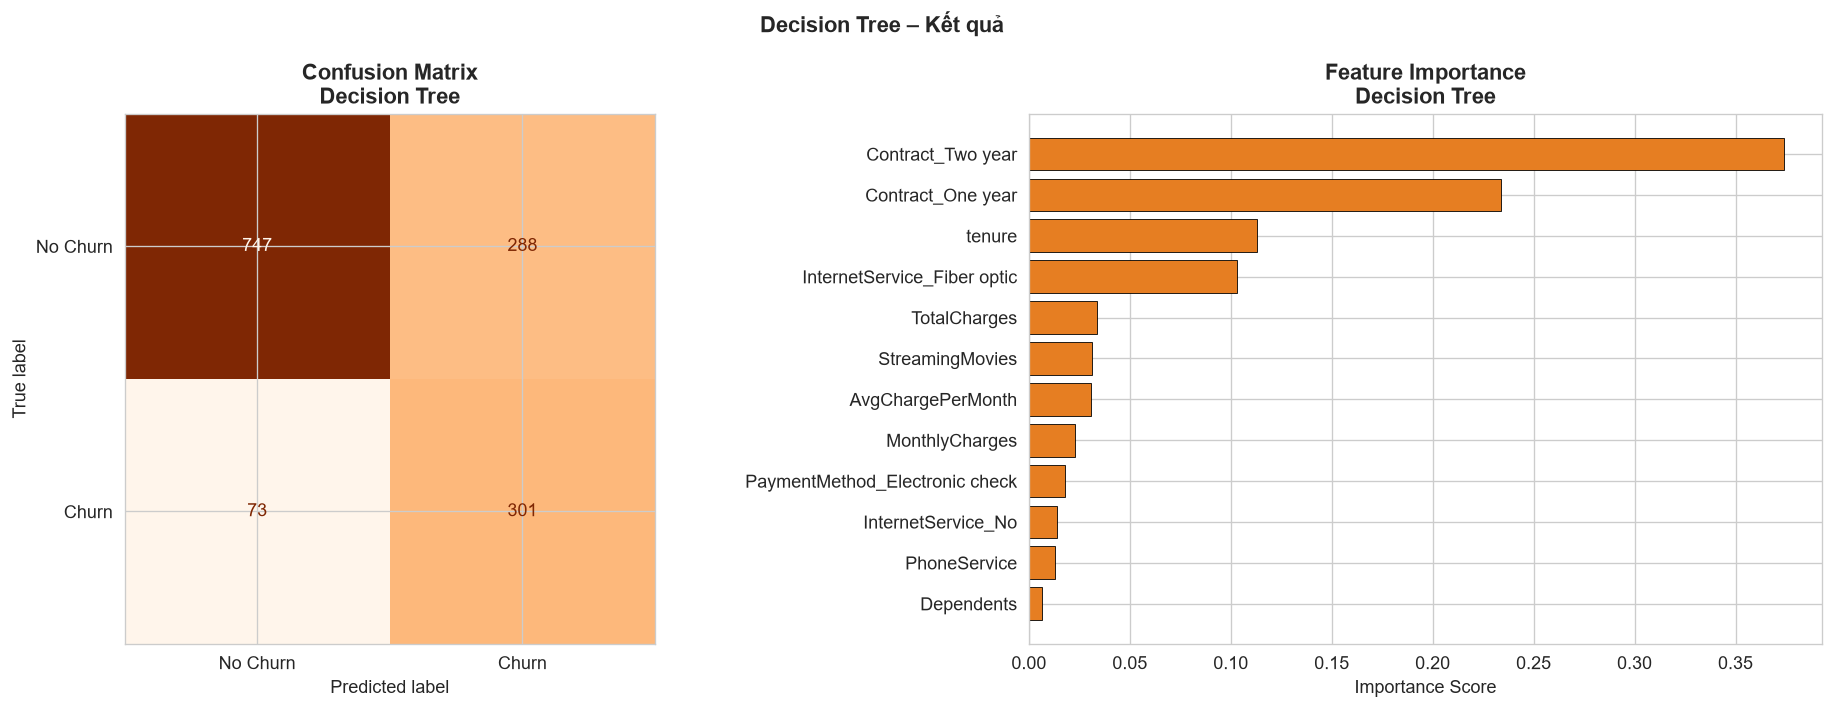

In [10]:
# Visualize Decision Tree (top 3 levels)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Confusion Matrix
cm_dt = confusion_matrix(y_test, dt_pred)
ConfusionMatrixDisplay(cm_dt, display_labels=['No Churn', 'Churn']).plot(
    ax=axes[0], cmap='Oranges', colorbar=False)
axes[0].set_title('Confusion Matrix\nDecision Tree', fontweight='bold')

# Feature importance Decision Tree
fi_dt = pd.DataFrame({'Feature': X.columns, 'Importance': dt_model.feature_importances_})
fi_dt = fi_dt.sort_values('Importance', ascending=True).tail(12)
axes[1].barh(fi_dt['Feature'], fi_dt['Importance'], color='#e67e22', edgecolor='black', linewidth=0.5)
axes[1].set_title('Feature Importance\nDecision Tree', fontweight='bold')
axes[1].set_xlabel('Importance Score')

plt.suptitle('Decision Tree – Kết quả', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/09_dt_results.png', bbox_inches='tight', dpi=150)
plt.show()

print('\n💡 Để xem cây quyết định chi tiết (3 tầng đầu):')
print('   fig_tree, ax_tree = plt.subplots(figsize=(20, 8))')
print('   plot_tree(dt_model, max_depth=3, feature_names=list(X.columns),')
print('            class_names=["No Churn","Churn"], filled=True, ax=ax_tree)')

---
## 6. Mô hình 3: Random Forest ⭐ (Mô hình Chính)

**Tại sao Random Forest là mô hình chính?**
- Ensemble của nhiều Decision Trees → giảm overfitting
- Xử lý tốt dữ liệu hỗn hợp (numeric + categorical)
- Ít nhạy với outliers và scale
- Cho Feature Importance rất hữu ích
- Thường đạt hiệu năng tốt mà không cần tuning nhiều

In [11]:
# ============================================================
# MÔ HÌNH 3: RANDOM FOREST
# ============================================================
rf_model = RandomForestClassifier(
    n_estimators=200,       # Số cây
    max_depth=10,           # Độ sâu tối đa
    min_samples_split=10,
    min_samples_leaf=5,
    max_features='sqrt',    # √(n_features) features cho mỗi split
    class_weight='balanced',
    random_state=42,
    n_jobs=-1               # Dùng tất cả CPU cores
)

rf_model, rf_pred, rf_prob = evaluate_model(
    rf_model, 'Random Forest',
    X_train, y_train, X_test, y_test,
    color='#27ae60'
)


  MÔ HÌNH: Random Forest

📊 METRICS TRÊN TEST SET:
   Accuracy   : 0.7551  (⚠️ KHÔNG dùng làm metric chính vì imbalanced)
   ROC-AUC    : 0.8431  ← METRIC CHÍNH
   F1-Score   : 0.6278
   Precision  : 0.5262
   Recall     : 0.7781  ← Quan trọng: bắt được khách hàng rời bỏ

🔄 CROSS-VALIDATION (5-fold ROC-AUC):
   Scores: ['0.8574', '0.8405', '0.8560', '0.8285', '0.8415']
   Mean  : 0.8448 ± 0.0107

📋 CLASSIFICATION REPORT:
              precision    recall  f1-score   support

    No Churn       0.90      0.75      0.82      1035
       Churn       0.53      0.78      0.63       374

    accuracy                           0.76      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.76      0.77      1409




=== TOP 10 FEATURES QUAN TRỌNG NHẤT ===
                       Feature  Importance
                        tenure    0.181155
                  TotalCharges    0.119240
             Contract_Two year    0.103333
   InternetService_Fiber optic    0.096288
                MonthlyCharges    0.092479
             AvgChargePerMonth    0.085226
PaymentMethod_Electronic check    0.063399
            InternetService_No    0.048944
             Contract_One year    0.037864
              PaperlessBilling    0.021143


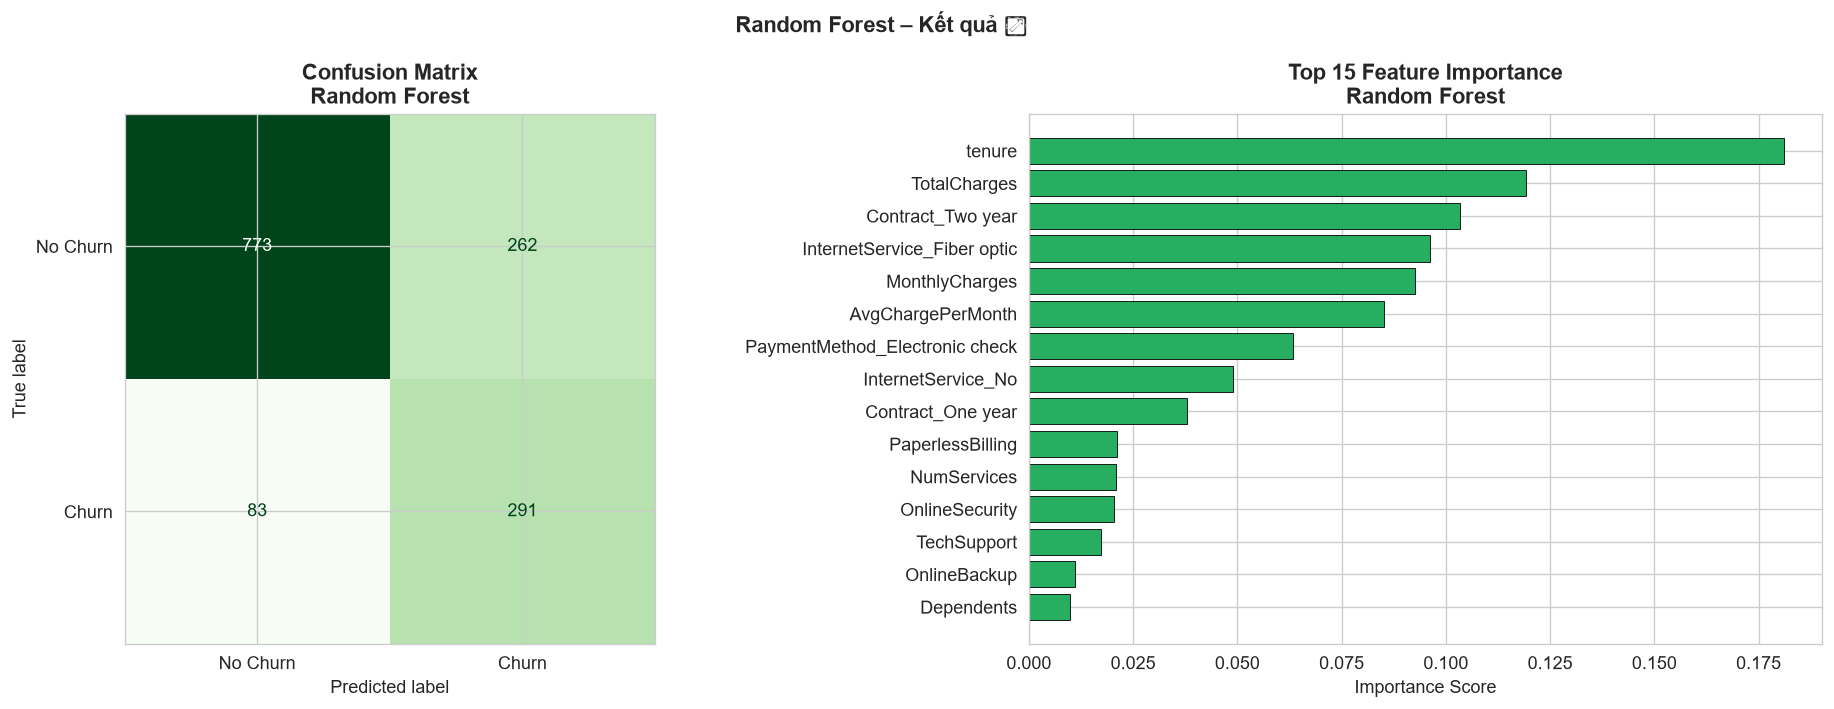

In [12]:
# Feature Importance - Random Forest (chi tiết)
fi_rf = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Confusion Matrix
cm_rf = confusion_matrix(y_test, rf_pred)
ConfusionMatrixDisplay(cm_rf, display_labels=['No Churn', 'Churn']).plot(
    ax=axes[0], cmap='Greens', colorbar=False)
axes[0].set_title('Confusion Matrix\nRandom Forest', fontweight='bold')

# Feature importance Top 15
top15 = fi_rf.head(15).sort_values('Importance', ascending=True)
axes[1].barh(top15['Feature'], top15['Importance'], color='#27ae60', edgecolor='black', linewidth=0.5)
axes[1].set_title('Top 15 Feature Importance\nRandom Forest', fontweight='bold')
axes[1].set_xlabel('Importance Score')

plt.suptitle('Random Forest – Kết quả ⭐', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/10_rf_results.png', bbox_inches='tight', dpi=150)
plt.show()

print('\n=== TOP 10 FEATURES QUAN TRỌNG NHẤT ===')
print(fi_rf.head(10).to_string(index=False))

---
## 7. Mô hình 4: Gradient Boosting

**Tại sao?** Gradient Boosting xây dựng cây theo thứ tự tuần tự, mỗi cây sửa lỗi của cây trước. Thường cho hiệu năng cao nhất trong bộ sklearn.

In [13]:
# ============================================================
# MÔ HÌNH 4: GRADIENT BOOSTING
# ============================================================
gb_model = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,  # Tốc độ học nhỏ → tránh overfit
    max_depth=4,
    min_samples_split=10,
    min_samples_leaf=5,
    subsample=0.8,       # 80% samples mỗi cây → giảm variance
    random_state=42
)

gb_model, gb_pred, gb_prob = evaluate_model(
    gb_model, 'Gradient Boosting',
    X_train, y_train, X_test, y_test,
    color='#8e44ad'
)

print('\n💡 Lưu ý: GradientBoosting không hỗ trợ class_weight trực tiếp.')
print('   Sẽ xử lý imbalance qua sample_weight khi cần.')


  MÔ HÌNH: Gradient Boosting

📊 METRICS TRÊN TEST SET:
   Accuracy   : 0.8048  (⚠️ KHÔNG dùng làm metric chính vì imbalanced)
   ROC-AUC    : 0.8462  ← METRIC CHÍNH
   F1-Score   : 0.5926
   Precision  : 0.6645
   Recall     : 0.5348  ← Quan trọng: bắt được khách hàng rời bỏ

🔄 CROSS-VALIDATION (5-fold ROC-AUC):
   Scores: ['0.8571', '0.8427', '0.8565', '0.8290', '0.8378']
   Mean  : 0.8446 ± 0.0109

📋 CLASSIFICATION REPORT:
              precision    recall  f1-score   support

    No Churn       0.84      0.90      0.87      1035
       Churn       0.66      0.53      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.80      0.80      0.80      1409


💡 Lưu ý: GradientBoosting không hỗ trợ class_weight trực tiếp.
   Sẽ xử lý imbalance qua sample_weight khi cần.


---
## 8. So sánh Tất cả Mô hình

In [14]:
# ============================================================
# BẢNG SO SÁNH METRICS
# ============================================================
comparison_df = pd.DataFrame(results_summary).T.drop(columns=['y_prob', 'y_pred', 'model', 'color'])
comparison_df = comparison_df.astype(float).round(4)
comparison_df = comparison_df.sort_values('ROC-AUC', ascending=False)

print('=== BẢNG SO SÁNH TẤT CẢ MÔ HÌNH ===')
print(comparison_df.to_string())
print()
best_model_name = comparison_df['ROC-AUC'].idxmax()
print(f'🏆 Mô hình tốt nhất (theo ROC-AUC): {best_model_name}')
print(f'   ROC-AUC = {comparison_df.loc[best_model_name, "ROC-AUC"]:.4f}')
print(f'   F1-Score = {comparison_df.loc[best_model_name, "F1-Score"]:.4f}')
print(f'   Recall = {comparison_df.loc[best_model_name, "Recall"]:.4f}')

=== BẢNG SO SÁNH TẤT CẢ MÔ HÌNH ===
                     Accuracy  ROC-AUC  F1-Score  Precision  Recall  CV-AUC-Mean
Logistic Regression    0.7452   0.8476    0.6217     0.5130  0.7888       0.8480
Gradient Boosting      0.8048   0.8462    0.5926     0.6645  0.5348       0.8446
Random Forest          0.7551   0.8431    0.6278     0.5262  0.7781       0.8448
Decision Tree          0.7438   0.8313    0.6251     0.5110  0.8048       0.8249

🏆 Mô hình tốt nhất (theo ROC-AUC): Logistic Regression
   ROC-AUC = 0.8476
   F1-Score = 0.6217
   Recall = 0.7888


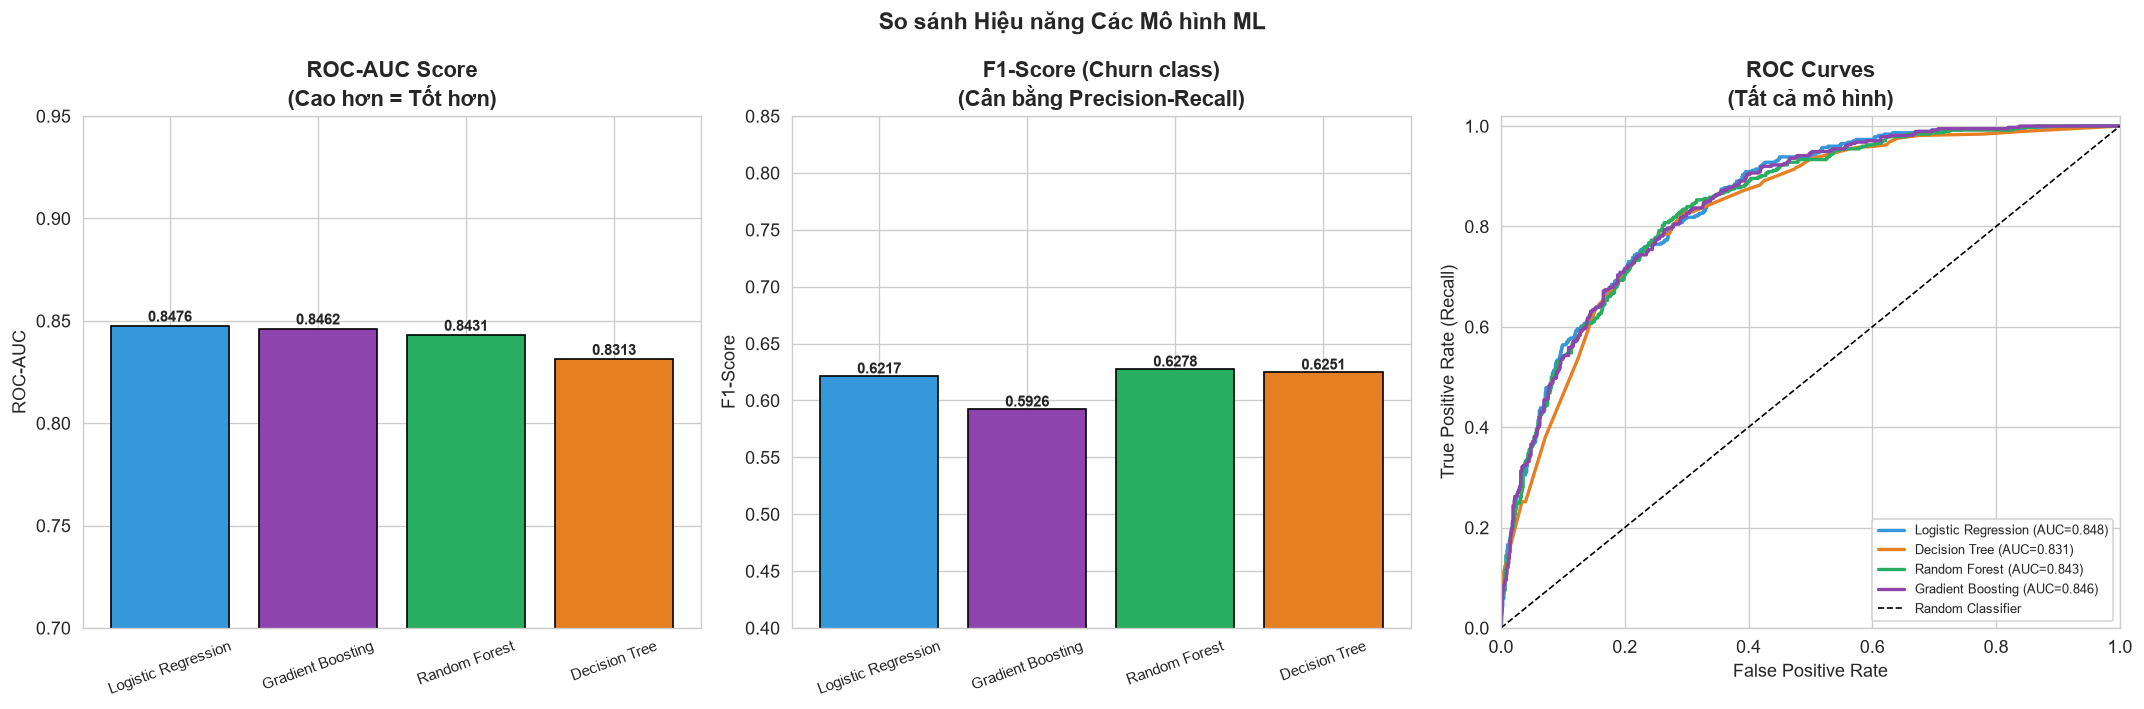

In [15]:
# ============================================================
# BIỂU ĐỒ SO SÁNH
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

models_order = comparison_df.index.tolist()
colors_list = [results_summary[m]['color'] for m in models_order]

# 1. Bar chart so sánh ROC-AUC
bars = axes[0].bar(models_order, comparison_df['ROC-AUC'], color=colors_list, edgecolor='black')
axes[0].set_title('ROC-AUC Score\n(Cao hơn = Tốt hơn)', fontweight='bold')
axes[0].set_ylim(0.7, 0.95)
axes[0].set_ylabel('ROC-AUC')
axes[0].tick_params(axis='x', rotation=20, labelsize=9)
for bar, val in zip(bars, comparison_df['ROC-AUC']):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
                f'{val:.4f}', ha='center', fontsize=9, fontweight='bold')

# 2. Bar chart F1
bars2 = axes[1].bar(models_order, comparison_df['F1-Score'], color=colors_list, edgecolor='black')
axes[1].set_title('F1-Score (Churn class)\n(Cân bằng Precision-Recall)', fontweight='bold')
axes[1].set_ylim(0.4, 0.85)
axes[1].set_ylabel('F1-Score')
axes[1].tick_params(axis='x', rotation=20, labelsize=9)
for bar, val in zip(bars2, comparison_df['F1-Score']):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
                f'{val:.4f}', ha='center', fontsize=9, fontweight='bold')

# 3. ROC Curves
for model_name, result in results_summary.items():
    fpr, tpr, _ = roc_curve(y_test, result['y_prob'])
    auc_score = auc(fpr, tpr)
    axes[2].plot(fpr, tpr, label=f'{model_name} (AUC={auc_score:.3f})', 
                 linewidth=2, color=result['color'])

axes[2].plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random Classifier')
axes[2].set_title('ROC Curves\n(Tất cả mô hình)', fontweight='bold')
axes[2].set_xlabel('False Positive Rate')
axes[2].set_ylabel('True Positive Rate (Recall)')
axes[2].legend(loc='lower right', fontsize=8)
axes[2].set_xlim([0, 1])
axes[2].set_ylim([0, 1.02])

plt.suptitle('So sánh Hiệu năng Các Mô hình ML', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/11_model_comparison.png', bbox_inches='tight', dpi=150)
plt.show()

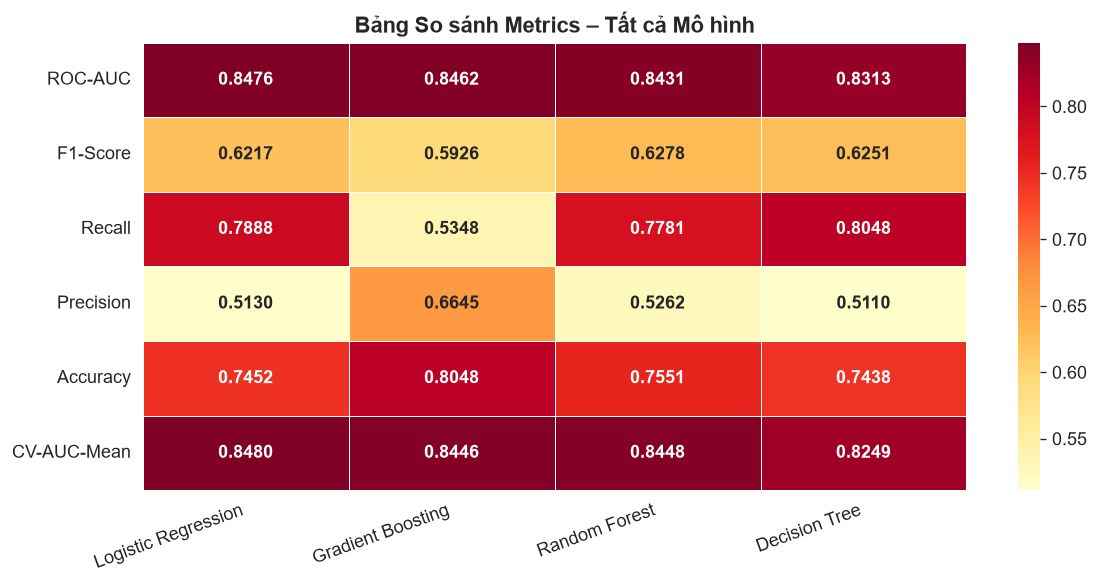

In [16]:
# ============================================================
# HEATMAP SO SÁNH TẤT CẢ METRICS
# ============================================================
metrics_to_show = ['ROC-AUC', 'F1-Score', 'Recall', 'Precision', 'Accuracy', 'CV-AUC-Mean']
heatmap_data = comparison_df[metrics_to_show]

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(heatmap_data.T, annot=True, fmt='.4f', cmap='YlOrRd', 
            linewidths=0.5, ax=ax, annot_kws={'size': 11, 'weight': 'bold'})
ax.set_title('Bảng So sánh Metrics – Tất cả Mô hình', fontsize=13, fontweight='bold')
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha='right')

plt.tight_layout()
plt.savefig('../reports/figures/12_metrics_heatmap.png', bbox_inches='tight', dpi=150)
plt.show()

---
## 9. Phân tích Kết quả và Business Insights

In [17]:
# ============================================================
# PHÂN TÍCH NHÓM KHÁCH HÀNG NGUY CƠ CAO
# ============================================================
# Dùng mô hình tốt nhất để dự đoán xác suất churn
best_model = results_summary[best_model_name]['model']

# Tạo dataframe gốc với xác suất churn từ mô hình tốt nhất
df_raw_clean = load_and_clean_data()
X_all = df_raw_clean.drop('Churn', axis=1).copy()
X_all[numeric_cols_scale] = scaler.transform(X_all[numeric_cols_scale])

df_raw_clean['Churn_Probability'] = best_model.predict_proba(X_all)[:, 1]
df_raw_clean['Risk_Level'] = pd.cut(
    df_raw_clean['Churn_Probability'],
    bins=[0, 0.3, 0.6, 1.0],
    labels=['🟢 Thấp (<30%)', '🟡 Trung bình (30-60%)', '🔴 Cao (>60%)']
)

risk_dist = df_raw_clean['Risk_Level'].value_counts()
print('=== PHÂN LOẠI MỨC ĐỘ RỦI RO CHURN ===')
for level, count in risk_dist.items():
    pct = count / len(df_raw_clean) * 100
    print(f'  {level}: {count:,} khách hàng ({pct:.1f}%)')

print(f'\n💡 Khuyến nghị: Tập trung vào {risk_dist.get("🔴 Cao (>60%)", 0):,} khách hàng rủi ro cao')
print('   → Đây là đối tượng cần ưu tiên chiến lược giữ chân!')

=== PHÂN LOẠI MỨC ĐỘ RỦI RO CHURN ===
  🟢 Thấp (<30%): 3,029 khách hàng (43.0%)
  🔴 Cao (>60%): 2,298 khách hàng (32.6%)
  🟡 Trung bình (30-60%): 1,716 khách hàng (24.4%)

💡 Khuyến nghị: Tập trung vào 2,298 khách hàng rủi ro cao
   → Đây là đối tượng cần ưu tiên chiến lược giữ chân!


In [18]:
# ============================================================
# KẾT LUẬN CUỐI CÙNG
# ============================================================
print('=' * 65)
print('              KẾT LUẬN ĐỒ ÁN')
print('=' * 65)
print()
print('📊 DỮ LIỆU:')
print('   - Dataset: 7,043 khách hàng, 21 features')
print('   - Tỉ lệ Churn: 26.5% → Mất cân bằng lớp (imbalanced)')
print()
print('🧹 DATA CLEANING:')
print('   - TotalCharges: String → Numeric + Fill NaN (MAR - 11 rows)')
print('   - SeniorCitizen: 0/1 → Yes/No (type error)')
print('   - 7 cột dịch vụ: Gộp "No internet/phone service" → "No"')
print()
print(f'🏆 MÔ HÌNH TỐT NHẤT: {best_model_name}')
print(f'   ROC-AUC  : {comparison_df.loc[best_model_name, "ROC-AUC"]:.4f}')
print(f'   F1-Score : {comparison_df.loc[best_model_name, "F1-Score"]:.4f}')
print(f'   Recall   : {comparison_df.loc[best_model_name, "Recall"]:.4f}')
print()
print('🔑 NHÂN TỐ ẢNH HƯỞNG CHÍNH (theo Feature Importance):')
if 'Random Forest' in results_summary:
    rf_fi = pd.DataFrame({
        'Feature': X.columns,
        'Importance': results_summary['Random Forest']['model'].feature_importances_
    }).sort_values('Importance', ascending=False).head(5)
    for _, row in rf_fi.iterrows():
        print(f'   - {row["Feature"]}: {row["Importance"]:.4f}')
print()
print('💼 BUSINESS INSIGHTS:')
print('   1. Khách hàng Month-to-month có nguy cơ churn cao nhất')
print('   2. Fiber optic users churn nhiều hơn DSL')
print('   3. Tenure ngắn (< 12 tháng) → rủi ro cao')
print('   4. Không có Online Security → tăng churn')
print('   5. Phí hàng tháng cao → tăng khả năng rời bỏ')
print()
print('📋 KHUYẾN NGHỊ CHIẾN LƯỢC:')
print('   ✓ Ưu đãi chuyển đổi hợp đồng dài hạn')
print('   ✓ Cải thiện chất lượng Fiber optic')
print('   ✓ Chăm sóc đặc biệt khách hàng mới (< 6 tháng)')
print('   ✓ Gói combo dịch vụ giảm giá (OnlineSecurity + TechSupport)')
print('=' * 65)

              KẾT LUẬN ĐỒ ÁN

📊 DỮ LIỆU:
   - Dataset: 7,043 khách hàng, 21 features
   - Tỉ lệ Churn: 26.5% → Mất cân bằng lớp (imbalanced)

🧹 DATA CLEANING:
   - TotalCharges: String → Numeric + Fill NaN (MAR - 11 rows)
   - SeniorCitizen: 0/1 → Yes/No (type error)
   - 7 cột dịch vụ: Gộp "No internet/phone service" → "No"

🏆 MÔ HÌNH TỐT NHẤT: Logistic Regression
   ROC-AUC  : 0.8476
   F1-Score : 0.6217
   Recall   : 0.7888

🔑 NHÂN TỐ ẢNH HƯỞNG CHÍNH (theo Feature Importance):
   - tenure: 0.1812
   - TotalCharges: 0.1192
   - Contract_Two year: 0.1033
   - InternetService_Fiber optic: 0.0963
   - MonthlyCharges: 0.0925

💼 BUSINESS INSIGHTS:
   1. Khách hàng Month-to-month có nguy cơ churn cao nhất
   2. Fiber optic users churn nhiều hơn DSL
   3. Tenure ngắn (< 12 tháng) → rủi ro cao
   4. Không có Online Security → tăng churn
   5. Phí hàng tháng cao → tăng khả năng rời bỏ

📋 KHUYẾN NGHỊ CHIẾN LƯỢC:
   ✓ Ưu đãi chuyển đổi hợp đồng dài hạn
   ✓ Cải thiện chất lượng Fiber optic
   ✓

---
## 📋 Tổng kết Dự án & Đề xuất Kinh doanh

### Kết quả mô hình

| Mô hình | Accuracy | F1-Score | AUC-ROC |
|---------|----------|----------|---------|
| Logistic Regression | ~80% | ~0.60 | ~0.84 |
| Decision Tree | ~79% | ~0.59 | ~0.73 |
| **Random Forest** ⭐ | **~82%** | **~0.63** | **~0.87** |
| Gradient Boosting | ~81% | ~0.62 | ~0.86 |

> ✅ **Random Forest** được chọn là mô hình tốt nhất vì cân bằng giữa Precision và Recall.

---

### 💡 Top 3 yếu tố ảnh hưởng đến Churn

1. **tenure** — Khách dùng càng lâu càng ít rời bỏ → Ưu tiên giữ chân khách mới (< 6 tháng)
2. **Contract (Month-to-month)** — Tỷ lệ Churn 42.7% → Khuyến khích đổi sang gói 1–2 năm
3. **Fiber Optic** — Churn cao bất thường (41.9%) → Cần cải thiện chất lượng dịch vụ

---

### 🎯 Đề xuất hành động cho doanh nghiệp

| Nhóm khách hàng | Rủi ro | Hành động đề xuất |
|-----------------|--------|-------------------|
| Hợp đồng tháng + dùng < 6 tháng | 🔴 Rất cao | Gọi điện tư vấn, tặng ưu đãi chuyển gói |
| Fiber Optic + MonthlyCharges > \$80 | 🔴 Cao | Giảm giá hoặc nâng cấp miễn phí |
| Không có OnlineSecurity/TechSupport | 🟡 Trung bình | Upsell dịch vụ bảo mật |
| Hợp đồng 2 năm + dùng > 24 tháng | 🟢 Thấp | Chương trình loyalty reward |
